# WP0 · Foundation

Artifacts every study S1–S7 reads. Built by `wp0/`, written to `wp0/out/`, hashed in `wp0/out/provenance.json`.

Nothing here reads `brainstormingsessions/v0/` except the explicit comparison cells, which are labelled.

Rebuild everything: `python -m wp0 run`. Check inputs have not drifted: `python -m wp0 verify`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Circle
from wp0 import io, registry, crosswalk, bands, solar, lai, report

# sequential blue ramp, steps 100->700; one hue, light->dark
BLUE = ['#cde2fb','#9ec5f4','#6da7ec','#3987e5','#2a78d6','#256abf','#184f95','#0d366b']
SEQ = LinearSegmentedColormap.from_list('seq_blue', BLUE)
INK, INK2, MUTED, SURFACE = '#0b0b0b', '#52514e', '#b8b7b2', '#fcfcfb'
mpl.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
                     'text.color': INK, 'axes.labelcolor': INK2,
                     'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.edgecolor': MUTED, 'font.size': 10})

OUT = io.OUT
reg   = pd.read_csv(OUT/'plot_centroid_registry.csv')
hls   = pd.read_csv(OUT/'crosswalk_plot_to_hls.csv')
modis = pd.read_csv(OUT/'crosswalk_plot_to_modis.csv')
refl  = pd.read_csv(OUT/'hf365_reflectance.csv')
clear = pd.read_csv(OUT/'interval_labelling_clear_days.csv')

# bracket access always: `.plot` is the pandas plotting accessor and 'plot' is our key
print(len(reg), 'plots |', hls['plot'].nunique(), 'plots in HLS crosswalk |',
      len(refl), 'reflectance rows')

46 plots | 46 plots in HLS crosswalk | 6773 reflectance rows


## Stage A · registry

46 EMS rows from `hf375-02`, WGS84 (stated in `hf375.xml`). Status and radii come from the `hf069.xml` abstract, not from the program document.

Two things the program document does not carry:
- the harvest group (A4, A5, B5, X1–X6) is **15 m radius from summer 2001**, not 10 m;
- **X4 ceased measurement in 2001** because the harvest did not affect it.

Caveat: the checks below are the *two-key* set — each is verified against a source outside `v0/`. Matching the program document's "values to verify" would prove only reproducibility, since those numbers were written from the v0 registry.

In [2]:
for label, ok, detail in registry.checks(reg):
    print(('PASS' if ok else 'FAIL'), label, ('| ' + detail) if detail else '')
print()
print(reg.groupby(['status','radius_m_post2001']).size().to_frame('n').to_string())

PASS 46 EMS rows in hf375-02 | 46
PASS 40 grid plots A1-H5 | 40
PASS 6 Simes plots X1-X6 
PASS 34 active tower plots (hf069.xml) | 34
PASS 8 harvest plots (hf069.xml) | 6 Simes + 3 moved = 9 rows; hf069.xml says 8 active because X4 ceased
PASS A1 == hf375-02 raw coordinate | 42.53735899, -72.17176138
PASS 8 lettered transects, not the ten hf069.xml claims | ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']

                                          n
status                radius_m_post2001    
active_tower          10.0               34
dropped_beaver_2001   10.0                3
harvest_active        15.0                5
harvest_ceased_2001   15.0                1
moved_to_harvest_2001 15.0                3


## Stage B · crosswalks

**MODIS was contested.** `v0/ems_plot_registry.csv` and `KillTest_ScalingBias.ipynb` disagreed on cell assignment. Adjudicated here against the tile/line/sample AppEEARS returns for the five downloaded pixels — an external key.

Result: the kill test was right. The v0 registry column is wrong for 7 of 34 active plots. Study 1's verdict does not move.

**HLS grid anchor is still unverified** — no T18TYN granule on disk. Every crosswalk row carries `grid_verified=False` until one arrives.

In [3]:
for label, ok, _ in crosswalk.validate_modis_grid():
    print(('PASS' if ok else 'FAIL'), label)

v0 = pd.read_csv(io.V0/'ems_plot_registry.csv')            # comparison target only
cmp = (modis[['plot','status','appeears_pixel']]
       .merge(v0[['plot','modis_pixel']], on='plot'))
cmp['v0'] = cmp['modis_pixel'].str.replace('_', '', regex=False)
act = cmp[cmp['status'] == 'active_tower']
agree = int((act['appeears_pixel'] == act['v0']).sum())
print(f'\nv0 registry vs adjudicated, active tower: {agree}/{len(act)} agree\n')
print(pd.crosstab(act['v0'], act['appeears_pixel']).to_string())

PASS AppEEARS pixel1 round-trips to h12v04 line=1790 sample=1636
PASS AppEEARS pixel2 round-trips to h12v04 line=1790 sample=1637
PASS AppEEARS pixel3 round-trips to h12v04 line=1791 sample=1635
PASS AppEEARS pixel4 round-trips to h12v04 line=1791 sample=1636
PASS AppEEARS pixel5 round-trips to h12v04 line=1791 sample=1637

v0 registry vs adjudicated, active tower: 27/34 agree

appeears_pixel  pixel1  pixel2  pixel3  pixel4  pixel5
v0                                                    
pixel1               7       0       0       0       0
pixel2               4       6       0       0       0
pixel3               0       0       2       0       0
pixel4               0       0       0      12       3


### Figure · plot footprints on the HLS grid

Each circle is one biometry plot at its surveyed radius; each square is one 30 m HLS pixel. Fill is the plot's overlap fraction with its dominant pixel — the quantity S1's pixel-assignment comparison turns on.

The 7 plots wholly inside a single pixel (heavy outline) are the only ones where the archive's single-pixel convention is unambiguous. Median dominant overlap for the 10 m plots is 0.769; the rest of the signal comes from neighbouring pixels.

Caveat: pixel edges are drawn on the assumed UTM-origin anchor, not a verified granule geotransform.

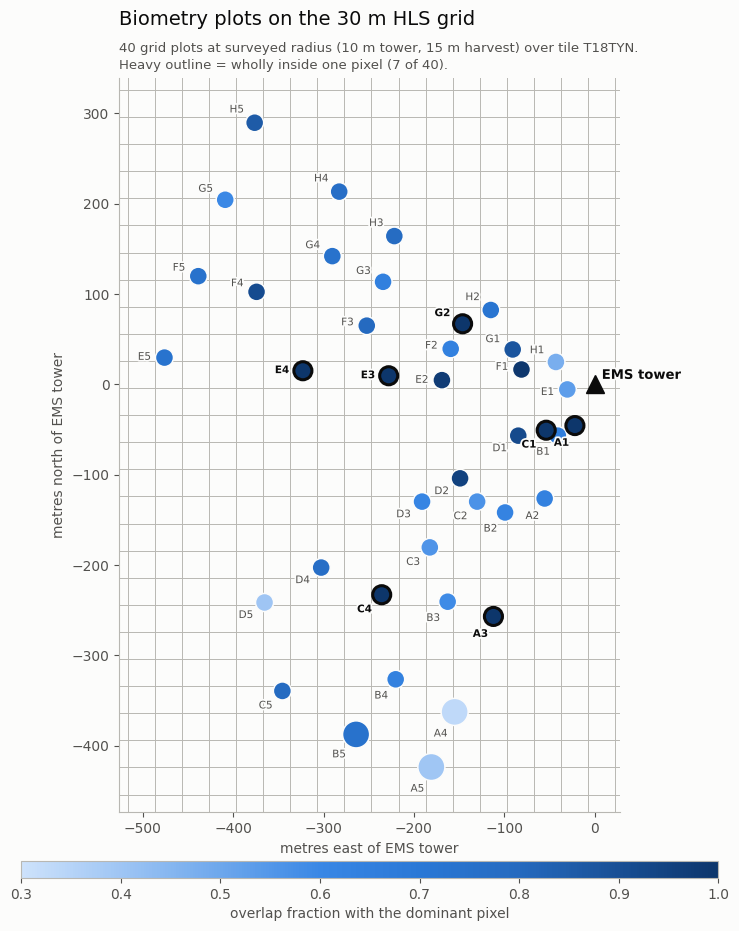

In [4]:
import matplotlib.patheffects as pe

dom = hls[hls['is_dominant']].set_index('plot')
sel = reg[reg['plot'].str.match(r'^[A-H][1-5]$')].copy()

# tower-relative metres: the raw UTM northing forces an unreadable 1e6 axis offset
TW_E, TW_N = 732277.0, 4713364.2
sel['x'] = sel['utm18n_e'] - TW_E
sel['y'] = sel['utm18n_n'] - TW_N
x0, x1 = sel.x.min() - 50, sel.x.max() + 50
y0, y1 = sel.y.min() - 50, sel.y.max() + 50

fig, ax = plt.subplots(figsize=(9.0, 10.6))

# the 30 m HLS grid, anchored on the UTM origin (unverified), shifted to tower-relative
gx0 = np.floor((TW_E + x0) / 30) * 30 - TW_E
gy0 = np.floor((TW_N + y0) / 30) * 30 - TW_N
for gx in np.arange(gx0, x1 + 30, 30):
    ax.axvline(gx, color=MUTED, lw=0.7, zorder=0)
for gy in np.arange(gy0, y1 + 30, 30):
    ax.axhline(gy, color=MUTED, lw=0.7, zorder=0)

norm = Normalize(0.3, 1.0)
halo = [pe.withStroke(linewidth=2.6, foreground=SURFACE)]
for _, p in sel.iterrows():
    f = float(dom.loc[p['plot'], 'overlap_frac'])
    inside = bool(dom.loc[p['plot'], 'fully_inside'])
    r = float(p['radius_m_post2001'])
    ax.add_patch(Circle((p['x'], p['y']), r, facecolor=SEQ(norm(f)),
                        edgecolor=INK if inside else SURFACE,
                        lw=2.2 if inside else 1.1, zorder=3 if inside else 2))
    # label radially outward from the tower, so the dense inner ring fans apart
    ang = np.arctan2(p['y'], p['x']) if (p['x'] or p['y']) else 0.0
    ux, uy = np.cos(ang), np.sin(ang)
    ax.annotate(p['plot'], (p['x'] + (r + 5) * ux, p['y'] + (r + 5) * uy),
                ha='left' if ux > 0.25 else ('right' if ux < -0.25 else 'center'),
                va='bottom' if uy > 0.25 else ('top' if uy < -0.25 else 'center'),
                fontsize=7.5, color=INK if inside else INK2,
                fontweight='bold' if inside else 'normal',
                path_effects=halo, zorder=4)

ax.plot(0, 0, marker='^', ms=13, color=INK, zorder=5)
ax.annotate('EMS tower', (8, 6), ha='left', fontsize=9.5, color=INK,
            fontweight='bold', path_effects=halo, zorder=5)

ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect('equal')
ax.set_xlabel('metres east of EMS tower'); ax.set_ylabel('metres north of EMS tower')
ax.set_title('Biometry plots on the 30 m HLS grid', loc='left',
             fontsize=14, color=INK, pad=38)
ax.annotate('40 grid plots at surveyed radius (10 m tower, 15 m harvest) over tile T18TYN.\n'
            'Heavy outline = wholly inside one pixel (7 of 40).',
            xy=(0, 1.008), xycoords='axes fraction', fontsize=9.5, color=INK2,
            va='bottom', linespacing=1.4)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)

cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=SEQ), ax=ax,
                  orientation='horizontal', fraction=0.04, pad=0.06, aspect=42)
cb.set_label('overlap fraction with the dominant pixel', color=INK2)
cb.outline.set_edgecolor(MUTED)
plt.show()

## Stage C · recovered reflectance

`NIR = NIRv/NDVI`, `RED = NIR(1−NDVI)/(1+NDVI)`, with EVI2 held out as an independent check.

The audit passes, so it produces no finding: recomputed EVI2 matches the archive to sd 0.00059 against a rounding-only floor of 0.00045 — the two agree to the limit of the 3-decimal storage. What the stage ships instead is the uncertainty envelope.

The three index files do **not** share a date index: 260 dates in all three, 263 in the union, non-nested in both directions. Every downstream join must declare which set it uses.

In [5]:
_, stats = bands.build()
for k in ['evi2_residual_sd','mc_floor_sd_median','red_rel_sd_growing_p50',
          'red_abs_sd_growing_p50','nir_rel_sd_growing_p50']:
    print(f'{k:28s} {stats[k]:.6f}')
ds = pd.read_csv(OUT/'hf365_date_sets.csv')
print(f'\ndates: union {len(ds)} | all three {int(ds.in_all_three.sum())} | '
      f'evi2 {int(ds.in_evi2.sum())} ndvi {int(ds.in_ndvi.sum())} nirv {int(ds.in_nirv.sum())}')
print('\nnot in all three:')
print(ds[~ds.in_all_three].to_string(index=False))

evi2_residual_sd             0.000592
mc_floor_sd_median           0.000449
red_rel_sd_growing_p50       0.003330
red_abs_sd_growing_p50       0.000073
nir_rel_sd_growing_p50       0.000882

dates: union 263 | all three 260 | evi2 261 ndvi 262 nirv 262

not in all three:
      date  in_evi2  in_ndvi  in_nirv  in_all_three
2019-07-12    False     True    False         False
2019-09-10    False     True     True         False
2020-07-21     True    False     True         False


## Stage D · solar geometry and stamp convention

fAPAR is a ratio of two PAR streams from different loggers, so a stamp-convention mismatch puts a systematic bias into every value — worst at high sun-angle rate of change, which is exactly where the paper's filters operate. Resolved here, before any fAPAR code exists.

Peak located by **parabola vertex** over the five points at the maximum. The intensity-weighted centroid is biased toward zero by afternoon convective cloud (it returned −0.35 h and drifted as the clear-day filter tightened); the vertex uses only the peak neighbourhood.

A stamp offset must be constant across the year. It is: month-by-month medians run −0.47 to −0.53 across March–October.

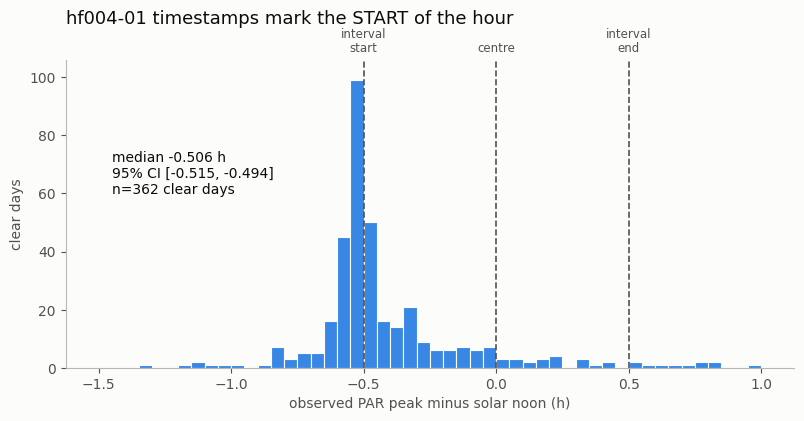

In [6]:
v = clear['lag_vertex_h'].dropna().to_numpy()
rng = np.random.default_rng(0)
bs = np.median(rng.choice(v, (4000, len(v))), axis=1)
med, lo, hi = np.median(v), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

fig, ax = plt.subplots(figsize=(9.4, 4.0))
ax.hist(v, bins=np.arange(-1.5, 1.05, 0.05), color=BLUE[3], edgecolor=SURFACE, lw=0.8)
top = ax.get_ylim()[1]
for x, lab in [(-0.5, 'interval\nstart'), (0.0, 'centre'), (0.5, 'interval\nend')]:
    ax.axvline(x, color=INK2, ls='--', lw=1.2, zorder=1)
    ax.annotate(lab, (x, 1.015), xycoords=('data', 'axes fraction'),
                ha='center', va='bottom', fontsize=8.5, color=INK2, linespacing=1.15)
ax.annotate(f'median {med:+.3f} h\n95% CI [{lo:+.3f}, {hi:+.3f}]\nn={len(v)} clear days',
            xy=(-1.45, top * 0.72), ha='left', va='top', fontsize=10, color=INK)
ax.set_ylim(0, top * 1.02)
ax.set_xlabel('observed PAR peak minus solar noon (h)')
ax.set_ylabel('clear days')
ax.set_title('hf004-01 timestamps mark the START of the hour', loc='left',
             fontsize=13, color=INK, pad=26)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.show()

## HF069-01 · roster, campaigns, PAI vs LAI

The column is named `lai` but holds plant area index — `hf069.xml` says so explicitly. Woody-corrected series ship as **variants**, never as a decision: printed vs subtractive equation, per-plot-year vs fixed extrema. S5's Arm A needs raw PAI alongside the corrected series, because a per-plot-year correction is year-relative and partly normalises away the between-year anomalies that study hunts.

The LAI-2000 → LAI-2200 change is documented qualitatively in `hf069.xml` ("comparisons between the two sensors showed consistent agreement"). Quantified below rather than raised with the authors.

In [7]:
df = pd.read_csv(OUT/'hf069_plot_clean.csv')
rej = pd.read_csv(OUT/'hf069_roster_rejects.csv')
print(f"{len(df)} rows | {df['plot'].nunique()} plots | {df.campaign_id.nunique()} campaigns | "
      f"{int((df.n_reps>1).sum())} rows from repeat measurements")
print('\nrejected labels:'); print(rej.to_string(index=False))
print('\ninstrument step test:')
for k, val in lai.instrument_step_test(df).items(): print(f'  {k}: {val}')

9922 rows | 46 plots | 288 campaigns | 103 rows from repeat measurements

rejected labels:
rejected_label  n_rows first_date  last_date
             1       1 2024-05-15 2024-05-15
         A1CAM       5 2011-04-22 2011-11-09
           BOG       1 2008-04-23 2008-04-23
           PAR     108 2006-05-17 2015-10-27
            RO       1 2010-11-19 2010-11-19
       RO TOWE       1 2010-10-28 2010-10-28
           TS1       2 2010-10-28 2010-11-19
           TS2       2 2010-10-28 2010-11-19
           VAN       1 2008-04-23 2008-04-23

instrument step test:
  n_plots: 33
  window_pre: 2010-2014
  window_post: 2015-2019
  mean_step_pai: 0.018958874458874488
  median_step_pai: 0.01774999999999949
  sd_step_pai: 0.3404003854914073
  t_stat: 0.31994805728445186
  p_paired_t: 0.7510874271338085
  p_wilcoxon: 0.6591820653993636
  verdict: no detectable step


## Archive corrections and the S6 answer key

`s6_audit/` was written after the program document's findings were known, so those cannot score it. Findings surfaced later are held out, and the freeze is enforced by hashing `s6_audit/` and `s6_search/` in `provenance.json` — `python -m wp0 verify` fails if either is edited.

Do not merge the `discovered_by` tags.

In [8]:
key = pd.read_json(OUT/'answer_key.jsonl', lines=True)
print(key.groupby(['discovered_by','usable_for_s6_eval']).size().to_frame('n').to_string())
print()
print(key[['id','dataset','fault_class','discovered_by']].to_string(index=False))
ok, problems = io.verify()
print('\nprovenance verify:', 'PASS' if ok else 'FAIL')
for p in problems: print('  !', p)

                                        n
discovered_by       usable_for_s6_eval   
planning_2026_08_07 True                5
program_doc         False               5
wp0_code            True                3

 id          dataset                    fault_class       discovered_by
F01         hf206-05           unconverted_sentinel         program_doc
F02         hf206-05               impossible_value         program_doc
F03         hf206-05              unit_error_in_eml         program_doc
F04         hf206-05    metadata_self_contradiction         program_doc
F05 hf069 / hf375-02          documentation_vs_data         program_doc
F06 hf375-02 / hf069 same_entity_inconsistent_value planning_2026_08_07
F07            hf365         internal_inconsistency planning_2026_08_07
F08         hf069-01              dirty_categorical planning_2026_08_07
F09         hf069-01      attribute_name_vs_content planning_2026_08_07
F10         hf069-01              duplicate_records planning_2026_08_